# MCDI505 — Sumativa 02
## Modelos clásicos de series de tiempo (ARIMA / SARIMA)
**Estudiante:** Luis Rodrigo Espinoza Muñoz  
**Docente:** Dr. Harvey Jezlid Rosas Quintero  
**Fecha:** 17 de octubre de 2026  
**Datos:** `data/raw/consumo_electrico_litoral_depurado.csv` (desde la raíz del proyecto)  
**Figuras:** `results/figures/` (desde la raíz del proyecto)

Comparo modelos clásicos y sus pronósticos. Incorporo la retroalimentación de Formativa 02 mediante una comprobación retrospectiva con origen móvil anual, sin utilizar 2024.


## Hoja de decisiones

| Criterio | Decisión | Evidencia clave (cifra, prueba o figura) | Alternativa descartada | Consecuencia |
|---|---|---|---|---|
| 1. Estacionariedad y transformaciones | Logaritmo; d = 1, D = 1, s = 12, usando solo 2015–2022. | ADF del nivel p = 0,2098; del log p = 0,1552; ambos KPSS p ≥ 0,10. Después: ADF p = 1,88×10⁻¹⁴ y KPSS p ≥ 0,10. Una diferencia adicional aumenta 97,03 % la varianza en soporte común (Tabla 1, Figuras 1–2). | Solo diferencia regular o estacional deja ADF sin rechazo al 5 %. d = 2 añade variación y ACF(1) negativa. | Interpretar discordancias y cambios estructurales; pronosticar en log y retransformar la media con la varianza predictiva. |
| 2. Identificación y estimación | Cuatro SARIMA: M1 (0,1,0)(0,1,1)₁₂; M2 (1,1,0)(0,1,1)₁₂; M3 (0,1,1)(0,1,1)₁₂; M4 (0,1,0)(1,1,0)₁₂. Máxima verosimilitud gaussiana, sin constante. | En la serie diferenciada: ACF(1) = 0,032; ACF(12) = −0,298; PACF(12) = −0,316 y PACF(24) = −0,358. Todos convergen (Tabla 2, Figura 3). | Grilla automática y copia del modelo de pasajeros: no hay un pico MA(1) regular claro. | Contrastar una lectura MA estacional con una AR estacional, sin afirmar cortes perfectos. |
| 3. Selección y comparación | M4 gana en la partición oficial 2023; su ventaja no se generaliza a los orígenes anteriores. M1 tiene menor error agregado. | RMSE M4/M1: 2021 = 8,839/5,041; 2022 = 9,965/5,909; 2023 = 4,123/7,202 GWh. Agregado 2021–2023: 8,050/6,115 GWh (Tabla 3, Figuras 4 y 4b). | Elegir un ganador universal usando solo 2023, o ignorar el mejor desempeño agregado de M1. | Se conserva M4 para el experimento oficial y su diagnóstico. Para uso en distintos períodos, M1 merece evaluación diagnóstica antes de adoptarlo; origen móvil retrospectivo, no test independiente. |
| 4. Diagnóstico de residuos | M4 utilizable con reservas; retirar 13 residuos iniciales y evaluar 83 innovaciones. | Ljung–Box p₁₂ = 0,6789 y p₂₄ = 0,0594; Shapiro p = 0,3924; ARCH-LM(12) p = 0,7952; media cero p = 0,9864 (Tabla 4, Figuras 5–6). | Declarar validez absoluta por un p > 0,05 o borrar el shock de 2020 para mejorar las pruebas. | No se rechazan los supuestos al 5 %, pero el resultado en rezago 24 es fronterizo. Intervalos gaussianos condicionales; vigilar estabilidad y dependencia residual. |

**Control de versión:** retroalimentación de Formativa 2 incorporada el 17 de octubre de 2026. Se mantienen estructura, escalera y comparación oficial; se añade origen móvil anual con reajuste en tres cortes y se actualiza la conclusión de robustez. 2024 permanece reservado.

## 0. Reproducibilidad del entorno y carga del dataset

El notebook está preparado para ejecutarse en orden mediante **Restart Kernel and Run All**. Se recomienda descargar o clonar el repositorio completo para disponer de `requirements.txt` y `data/raw/consumo_electrico_litoral_depurado.csv`. La instalación de las dependencias necesita Internet; una vez instaladas, el análisis utiliza el CSV local.

La raíz del proyecto se detecta automáticamente desde la carpeta principal, `notebooks/` o `notebooks/notebook_formativa/`. Se usan rutas con `pathlib`, compatibles con macOS, Windows y Linux. Todas las figuras se muestran dentro del notebook y se guardan como PNG en `results/figures/`.

**Instalación local en macOS o Linux (desde la raíz del repositorio):**

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install --upgrade pip
python -m pip install -r requirements.txt
python -m ipykernel install --user --name mcdi505 --display-name "Python (MCDI505)"
jupyter lab
```

**Instalación local en Windows PowerShell (desde la raíz del repositorio):**

```powershell
py -m venv .venv
.\.venv\Scripts\Activate.ps1
python -m pip install --upgrade pip
python -m pip install -r requirements.txt
python -m ipykernel install --user --name mcdi505 --display-name "Python (MCDI505)"
jupyter lab
```

Si PowerShell bloquea la activación, ejecutar `Set-ExecutionPolicy -Scope Process -ExecutionPolicy Bypass` y volver a activar el entorno. Seleccionar el kernel **Python (MCDI505)**, abrir `notebooks/notebook_formativa/mcdi505_s2lespinoza.ipynb` y ejecutar todas las celdas en orden. El entorno `.venv` se crea en cada computador; no se copia entre sistemas operativos.

**Google Colab:** subir el notebook y ejecutar primero en una celda adicional:

```python
%pip install pandas numpy scipy matplotlib statsmodels
```

En el panel de archivos, crear `data/raw/` dentro del directorio de trabajo y subir allí `consumo_electrico_litoral_depurado.csv`. Luego ejecutar el notebook desde el inicio. No se necesita `.venv` ni registrar un kernel local. Al terminar, descargar el notebook ejecutado y las figuras de `results/figures/`, ya que los archivos del entorno de Colab son temporales. El CSV debe acompañar al notebook: no se ha configurado una fuente pública de respaldo.

**Alcance de la reproducibilidad:** el entorno local se ha validado en macOS con Python 3.10.4. Las instrucciones para Windows, Linux y Colab describen cómo prepararlo, pero no constituyen pruebas ejecutadas en esas plataformas. Se registran las versiones utilizadas en la siguiente celda; `requirements.txt` no fija versiones, por lo que una instalación futura puede usar versiones distintas. Para el error de SciPy `_spropack` / `__thread_bss` en macOS ARM64, consultar la solución específica del entorno Python 3.10 en `README.md`.

Cargo el CSV depurado sin modificarlo ni repetir sus correcciones. Uso 2015–2022 para entrenamiento y 2023 para validación; 2024 queda reservado. Registro las versiones y la huella SHA-256 del archivo. La semilla se fija en 505, aunque los ajustes utilizados son deterministas.


**Comprobación de esta revisión (17 de octubre de 2026):** todas las celdas de código se ejecutaron en orden, sin errores, en un proceso IPython nuevo con Python 3.12.14; se guardaron salidas y figuras. Se verificó que el origen diciembre de 2022 reproduce los pronósticos originales de 2023. Esta comprobación no equivale a ejecutar el comando de interfaz «Restart Kernel and Run All» en el equipo local. Las versiones efectivamente usadas se muestran en la siguiente celda.

In [1]:
# importar las librerías para el análisis y el diagnóstico
from pathlib import Path
import sys, hashlib, warnings, importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tools.sm_exceptions import InterpolationWarning

# definir la semilla, significancia y período anual
SEMILLA, ALFA, PERIODO = 505, 0.05, 12
np.random.seed(SEMILLA)
# Solo silenciar avisos de transición de API, nunca avisos de convergencia.
warnings.filterwarnings('ignore', category=FutureWarning, message='.*currently returns a plain tuple.*')
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
# localizar el proyecto desde la carpeta del notebook o la raíz
nombre_csv = 'consumo_electrico_litoral_depurado.csv'
project_root = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / 'data/raw' / nombre_csv).is_file()), None
)
if project_root is None:
    raise FileNotFoundError('Ejecuta el notebook dentro del proyecto que contiene data/raw/consumo_electrico_litoral_depurado.csv.')

# guardar las figuras en la carpeta de resultados del proyecto
FIGURAS = project_root / 'results/figures'
FIGURAS.mkdir(parents=True, exist_ok=True)
def mostrar_figura(fig, nombre):
    # ajustar, guardar y mostrar cada figura
    fig.tight_layout()
    fig.savefig(FIGURAS / nombre, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

# leer únicamente el CSV depurado de data/raw/
ruta = project_root / 'data/raw' / nombre_csv
# registrar la huella para identificar la versión de los datos
sha256 = hashlib.sha256(ruta.read_bytes()).hexdigest()
sha_esperado = 'd308b3605bf47ed8687676906a130362d899cfcf5e40329a39c9074078c0c3d1'
print('SHA-256:', sha256)
if sha256 != sha_esperado:
    warnings.warn('El archivo difiere en bytes del analizado; revise procedencia y resultados.')
# cargar los datos y comprobar fechas y columnas
df = pd.read_csv(ruta, parse_dates=['fecha'], index_col='fecha')
assert df.index.is_unique and df.index.is_monotonic_increasing
assert {'consumo_gwh','consumo_gwh_original','imputado','atipico_corregido','covid'} <= set(df.columns)
# La verificación del calendario no usa valores de consumo de 2024.
assert df.index.equals(pd.date_range(df.index.min(), df.index.max(), freq='MS'))
# separar el período de análisis sin utilizar 2024
datos = df.loc['2015-01':'2023-12'].copy().asfreq('MS')
y = datos['consumo_gwh'].astype(float)
assert len(y) == 108 and y.notna().all() and np.isfinite(y).all() and (y > 0).all()
# mantener el orden temporal entre entrenamiento y validación
y_train, y_val = y.loc['2015':'2022'], y.loc['2023']
assert len(y_train) == 96 and len(y_val) == 12
assert y_train.index.max() < y_val.index.min()
# comprobar las correcciones e indicadores del archivo depurado
assert int(datos.imputado.sum()) == 3 and int(datos.atipico_corregido.sum()) == 1
assert datos.loc['2017-11-01','atipico_corregido'] == 1
assert datos.covid.astype(bool).equals(pd.Series(
    (datos.index >= '2020-03-01') & (datos.index <= '2021-12-01'), index=datos.index))
# transformar solo la serie de entrenamiento
z_train = np.log(y_train)
print('Entrenamiento: 2015-01 a 2022-12 (96 meses). Validación: 2023 (12 meses).')
print('2024 excluido de gráficos, estimación, selección y métricas.')
print('Indicadores 2015–2023:', datos[['imputado','atipico_corregido','covid']].sum().to_dict())
print('Python:', sys.version.split()[0])
print('Versiones:', {p: metadata.version(p) for p in ['numpy','pandas','scipy','statsmodels','matplotlib']})

SHA-256: d308b3605bf47ed8687676906a130362d899cfcf5e40329a39c9074078c0c3d1
Entrenamiento: 2015-01 a 2022-12 (96 meses). Validación: 2023 (12 meses).
2024 excluido de gráficos, estimación, selección y métricas.
Indicadores 2015–2023: {'imputado': 3, 'atipico_corregido': 1, 'covid': 22}
Python: 3.10.4
Versiones: {'numpy': '2.2.6', 'pandas': '2.3.3', 'scipy': '1.15.3', 'statsmodels': '0.15.0', 'matplotlib': '3.10.9'}


Distribuidora Eléctrica del Litoral (DEL) se analiza mediante su consumo mensual en GWh. Se usa el CSV depurado indicado por las instrucciones, sin repetir imputaciones ni corregir nuevamente noviembre de 2017. El análisis mantiene un enfoque univariado; clientes, temperatura, días hábiles y COVID aportan contexto, pero no se incorporan como regresores. A diferencia de la Sumativa 1, que conservaba el atípico, esta etapa adopta la corrección oficial. El objetivo es comparar pronósticos a 12 pasos originados en diciembre de 2022 y diagnosticar el modelo seleccionado (Universidad Andrés Bello, s. f.-a).

**Retroalimentación recibida de Sumativa 1:** mantener fuera los datos de 2024, argumentar cada decisión con evidencia y traducir el diagnóstico en transformación y diferenciación. Se atiende mediante la partición explícita, la escalera de Tabla 1, los correlogramas y la trazabilidad de la hoja de decisiones. La retroalimentación posterior de Formativa 2 se incorpora en la sección 3 mediante la validación con origen móvil.

## 1. Análisis de estacionariedad y transformaciones

**ID 2.2.** ADF: H₀ = raíz unitaria; KPSS: H₀ = estacionariedad alrededor de una constante. Se usa α = 0,05, ADF con rezagos por AIC y KPSS con ancho de banda automático. La escalera se evalúa únicamente en entrenamiento (Hyndman & Athanasopoulos, 2021, cap. 9; Rosas, 2026).

Tabla 1. Escalera de diferenciación (varianzas entre escalas no comparables).


,n,Varianza,ADF,p ADF,lags ADF,KPSS,p KPSS,lags KPSS
Serie,,,,,,,,
Nivel (GWh),96,146.287567,-2.190,0.21,12,0.259,"≥ 0,10",4
"Log, d=0 D=0",96,0.014153,-2.354,0.155,12,0.261,"≥ 0,10",4
"Log, d=1 D=0",95,0.006438,-2.667,0.08,11,0.036,"≥ 0,10",1
"Log, d=0 D=1",84,0.007204,-2.563,0.101,0,0.222,"≥ 0,10",5
"Log, d=1 D=1",83,0.002192,-8.820,1.88e-14,0,0.040,"≥ 0,10",1
"Log, d=2 D=1",82,0.004167,-7.251,1.78e-10,4,0.158,"≥ 0,10",23


Diferencia adicional: varianza +97.03% en 82 fechas comunes.
Amplitud anual relativa (%): {2015: 31.77, 2016: 30.33, 2017: 30.26, 2018: 35.1, 2019: 29.99, 2020: 53.63, 2021: 31.51, 2022: 22.55}


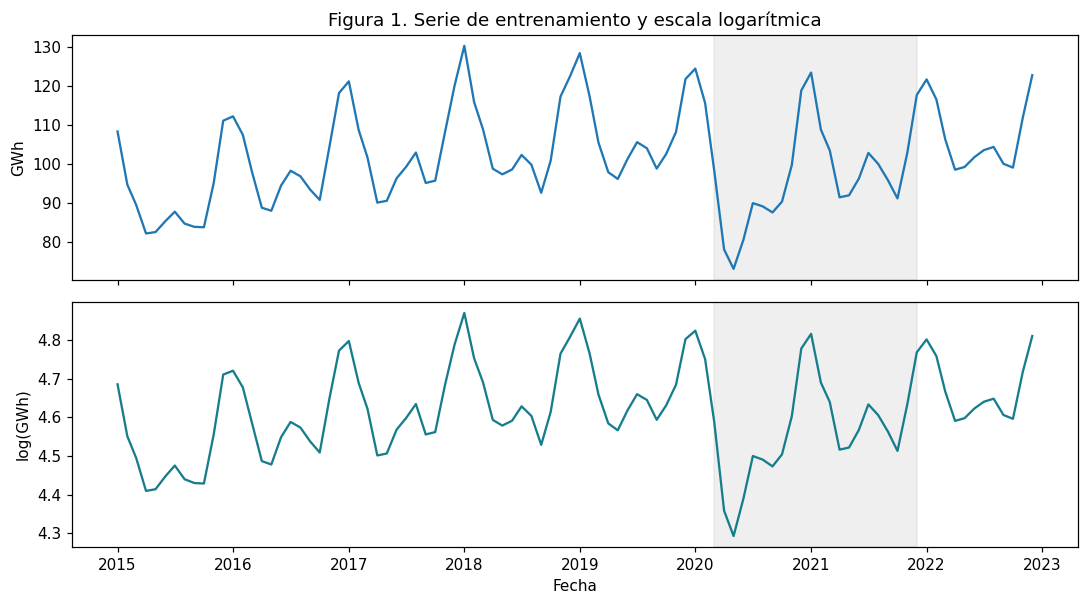

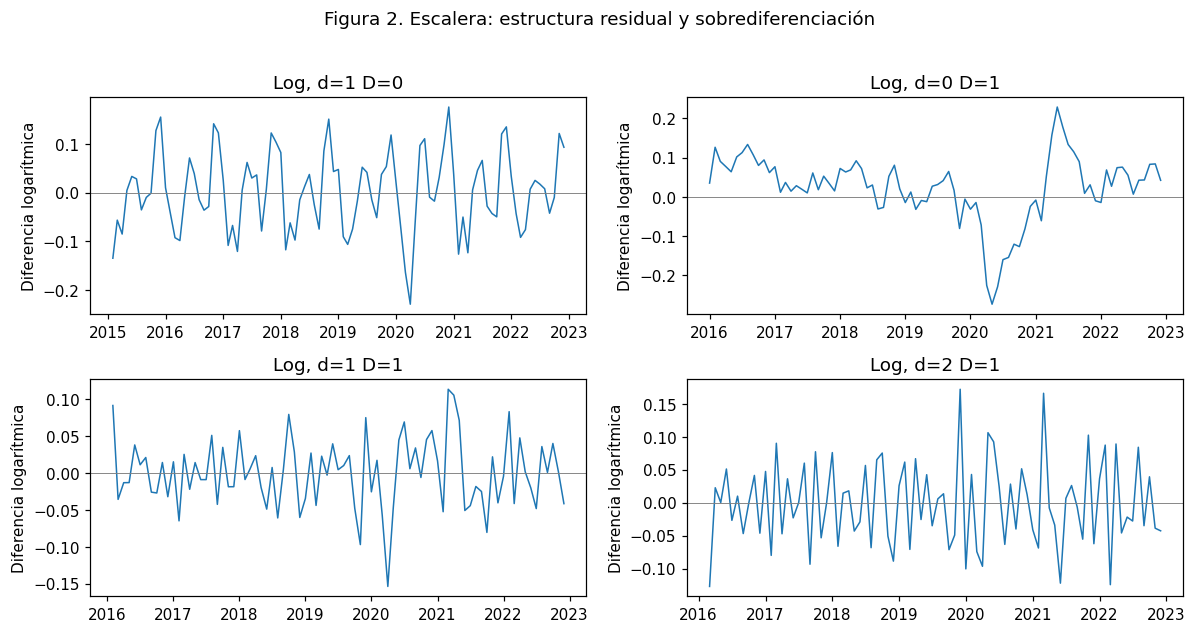

In [2]:
# comparar diferencias regulares y estacionales en entrenamiento
escalera = {
    'Nivel (GWh)': y_train,
    'Log, d=0 D=0': z_train,
    'Log, d=1 D=0': z_train.diff(),
    'Log, d=0 D=1': z_train.diff(12),
    'Log, d=1 D=1': z_train.diff(12).diff(),
    'Log, d=2 D=1': z_train.diff(12).diff().diff()
}
# mostrar los límites de los p-valores tabulados
def etiqueta_kpss(p):
    return '≥ 0,10' if p >= .1 else ('≤ 0,01' if p <= .01 else f'{p:.4f}')
# reunir las pruebas de cada transformación
filas = []
for nombre, serie in escalera.items():
    s = serie.dropna()
    a = adfuller(s, regression='c', autolag='AIC')
    # KPSS devuelve límites tabulados, no p-valores exactos en las colas.
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', InterpolationWarning)
        k = kpss(s, regression='c', nlags='auto')
    filas.append([nombre, len(s), s.var(ddof=1), a[0], a[1], a[2],
                  k[0], etiqueta_kpss(k[1]), k[2]])
tabla1 = pd.DataFrame(filas, columns=['Serie','n','Varianza','ADF','p ADF',
                                      'lags ADF','KPSS','p KPSS','lags KPSS']).set_index('Serie')
print('Tabla 1. Escalera de diferenciación (varianzas entre escalas no comparables).')
display(tabla1.style.format({'Varianza':'{:.6f}','ADF':'{:.3f}',
                            'p ADF':'{:.3g}','KPSS':'{:.3f}'}))
# comparar la varianza sobre las mismas fechas
w = escalera['Log, d=1 D=1'].dropna()
comun = pd.concat([w, escalera['Log, d=2 D=1']], axis=1).dropna()
aumento_varianza = 100*(comun.iloc[:,1].var()/comun.iloc[:,0].var()-1)
print(f'Diferencia adicional: varianza +{aumento_varianza:.2f}% en {len(comun)} fechas comunes.')
# resumir la amplitud relativa de cada año
anual = y_train.groupby(y_train.index.year).agg(['mean','min','max'])
amplitud_relativa = 100*(anual['max']-anual['min'])/anual['mean']
print('Amplitud anual relativa (%):', amplitud_relativa.round(2).to_dict())
# visualizar la serie y sus transformaciones
fig, ax = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True)
ax[0].plot(y_train); ax[0].set(title='Figura 1. Serie de entrenamiento y escala logarítmica', ylabel='GWh')
ax[1].plot(z_train, color='#167d8d'); ax[1].set(ylabel='log(GWh)', xlabel='Fecha')
for a in ax: a.axvspan(pd.Timestamp('2020-03-01'),pd.Timestamp('2021-12-01'),alpha=.12,color='gray')
mostrar_figura(fig, 's2_01_serie.png')
# mostrar los patrones residuales de cada combinación de diferencias
fig, ax = plt.subplots(2, 2, figsize=(11, 5.6))
for a, nombre in zip(ax.flat, list(escalera)[2:]):
    s = escalera[nombre].dropna(); a.plot(s, lw=1)
    a.axhline(0, color='gray', lw=.6); a.set(title=nombre, ylabel='Diferencia logarítmica')
fig.suptitle('Figura 2. Escalera: estructura residual y sobrediferenciación', y=1.02)
mostrar_figura(fig, 's2_02_escalera.png')


### Interpretación

El logaritmo es admisible porque todos los consumos son positivos. La amplitud relativa anual presenta valores próximos al 30 % en varios años; la perturbación de 2020 limita esa regularidad. Se adopta la transformación para expresar variaciones relativas y moderar el efecto del nivel, sin afirmar que garantice varianza constante ni que supere a Box–Cox. No se comparan directamente varianzas en GWh² y en escala logarítmica.

En niveles, ADF no rechaza raíz unitaria (p = 0,2098), mientras KPSS no rechaza estacionariedad (p ≥ 0,10). El logaritmo conserva esta discordancia. Ninguna prueba por sí sola resuelve la decisión: influyen la muestra corta, la estacionalidad y las perturbaciones de nivel.

La diferencia regular sola mantiene ADF p = 0,0800; la estacional sola, p = 0,1009. Con d = 1 y D = 1, ADF rechaza (p = 1,88×10⁻¹⁴) y KPSS no rechaza (p ≥ 0,10). Se adopta esta especificación con s = 12, en conjunto con la inspección gráfica.

Añadir otra diferencia regular eleva la varianza de 0,002115 a 0,004167 en las mismas 82 fechas (+97,03 %) y genera ACF(1) = −0,425. ADF también rechaza en ese peldaño: no detecta por sí solo la sobrediferenciación. La decisión no elimina el shock de 2020 ni demuestra estacionariedad estricta; respalda una aproximación de segundo orden para modelar.

## 2. Identificación y estimación de modelos

**ID 2.1.** Los candidatos se proponen a partir de la serie estacionarizada, antes de comparar errores de validación. Se usa SARIMAX como implementación de SARIMA **sin variables exógenas**. Todos comparten logaritmo, d = D = 1, s = 12, período de entrenamiento e inicialización; no se usa AutoARIMA (Rosas, 2026).

n=83, banda blanca aproximada ±0.215; 36×0,05=1.8 cruces esperados por azar por gráfico.
Rezagos 1, 12, 24, 36; ACF: [ 0.032 -0.298 -0.213  0.002] ; PACF: [ 0.032 -0.316 -0.358 -0.185]


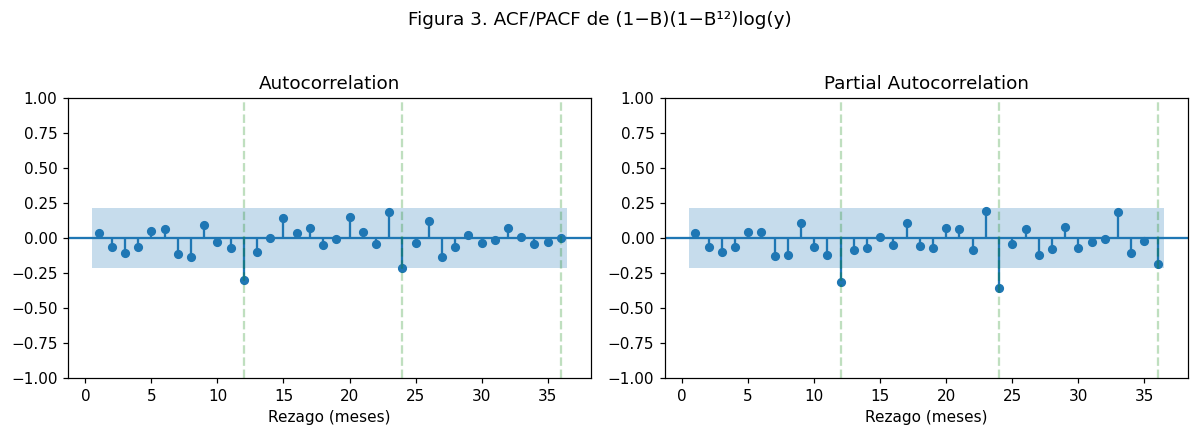

Tabla 2. Identificación y estimación por máxima verosimilitud gaussiana.


,Órdenes,Fundamento,Coeficientes (EE),sigma²,Converge,Avisos
Modelo,,,,,,
M1,"(0, 1, 0)(0, 1, 1, 12)",ACF(12) negativa; sin pico regular claro: MA estacional parsimonioso.,ma.S.L12=-0.9712 (EE 1.4166),0.001145,True,0
M2,"(1, 1, 0)(0, 1, 1, 12)","Sensibilidad: posible persistencia regular débil como AR(1), no corte probado.",ar.L1=-0.0434 (EE 0.0903); ma.S.L12=-0.9686 (EE 1.3084),0.001147,True,0
M3,"(0, 1, 1)(0, 1, 1, 12)",Sensibilidad: MA(1) regular frente a AR(1); no se presupone modelo de aerolínea.,ma.L1=-0.0507 (EE 0.0879); ma.S.L12=-0.9705 (EE 1.3889),0.001143,True,0
M4,"(0, 1, 0)(1, 1, 0, 12)","Lectura alternativa AR estacional; ACF(24) menor en magnitud, corte PACF imperfecto.",ar.S.L12=-0.3109 (EE 0.1013),0.001934,True,0


In [3]:
# examinar hasta tres ciclos anuales
rezagos = 36
r_acf, r_pacf = acf(w, nlags=rezagos), pacf(w, nlags=rezagos, method='ywm')
banda = 1.96 / np.sqrt(len(w))
print(f'n={len(w)}, banda blanca aproximada ±{banda:.3f}; 36×0,05={36*.05:.1f} cruces esperados por azar por gráfico.')
print('Rezagos 1, 12, 24, 36; ACF:', np.round(r_acf[[1,12,24,36]],3),
      '; PACF:', np.round(r_pacf[[1,12,24,36]],3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
plot_acf(w, lags=rezagos, zero=False, ax=ax[0], bartlett_confint=False)
plot_pacf(w, lags=rezagos, zero=False, method='ywm', ax=ax[1])
for a in ax:
    for lag in [12,24,36]: a.axvline(lag, color='green', alpha=.25, ls='--')
    a.set_xlabel('Rezago (meses)')
fig.suptitle('Figura 3. ACF/PACF de (1−B)(1−B¹²)log(y)', y=1.03)
mostrar_figura(fig, 's2_03_correlogramas.png')
# definir modelos a partir de los correlogramas
candidatos = {
 'M1': ((0,1,0),(0,1,1,12),'ACF(12) negativa; sin pico regular claro: MA estacional parsimonioso.'),
 'M2': ((1,1,0),(0,1,1,12),'Sensibilidad: posible persistencia regular débil como AR(1), no corte probado.'),
 'M3': ((0,1,1),(0,1,1,12),'Sensibilidad: MA(1) regular frente a AR(1); no se presupone modelo de aerolínea.'),
 'M4': ((0,1,0),(1,1,0,12),'Lectura alternativa AR estacional; ACF(24) menor en magnitud, corte PACF imperfecto.')
}
# ajustar cada candidato y registrar su convergencia
ajustes, registro = {}, []
for nombre, (orden, estacional, motivo) in candidatos.items():
    modelo = SARIMAX(z_train, order=orden, seasonal_order=estacional, trend='n',
                     enforce_stationarity=True, enforce_invertibility=True,
                     simple_differencing=False)
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always')
        ajuste = modelo.fit(method='lbfgs', maxiter=500, disp=False)
        if not ajuste.mle_retvals.get('converged',False):
            ajuste = modelo.fit(method='powell', maxiter=1000, disp=False)
    assert ajuste.mle_retvals.get('converged',False), f'{nombre}: no convergió'
    assert np.isfinite(ajuste.params).all()
    ajustes[nombre] = ajuste
    # resumir coeficientes y errores estándar
    errores = ajuste.bse
    coef = '; '.join(f'{p}={v:.4f} (EE {errores[p]:.4f})'
                     for p,v in ajuste.params.items() if p != 'sigma2')
    registro.append([nombre, str(orden)+str(estacional), motivo,coef,
                     ajuste.params['sigma2'], ajuste.mle_retvals['converged'],len(avisos)])
    for aviso in avisos: print(f'Aviso {nombre}: {aviso.message}')
# comparar los ajustes estimados
tabla2 = pd.DataFrame(registro,columns=['Modelo','Órdenes','Fundamento','Coeficientes (EE)',
                                      'sigma²','Converge','Avisos']).set_index('Modelo')
print('Tabla 2. Identificación y estimación por máxima verosimilitud gaussiana.')
display(tabla2.style.format({'sigma²':'{:.6f}'}))


### Interpretación

Los rezagos regulares 1–11 no muestran un patrón inequívoco: ACF(1) = 0,032 es pequeña. En el bloque estacional, ACF(12) = −0,298 y PACF(12) = −0,316 exceden la banda aproximada ±0,215. PACF(24) = −0,358 impide hablar de un corte AR estacional limpio. Las bandas son puntuales; con 36 rezagos se esperan aproximadamente 1,8 cruces fortuitos bajo ruido blanco, sin asumir independencia entre barras.

M1 propone un MA estacional sin términos regulares. M2 y M3 añaden, respectivamente, AR(1) y MA(1) como sensibilidades acotadas frente a dependencia regular débil; no representan firmas visuales confirmadas. M4 contrasta una lectura AR estacional de primer orden. Los cuatro comparten diferenciación y escala; la elección se contrasta cuantitativamente, no mediante una grilla extensa.

Todos convergen. Los términos regulares estimados de M2 y M3 son pequeños. Los MA estacionales de M1–M3 quedan próximos a −1: aun con invertibilidad impuesta, esta cercanía a la frontera aconseja prudencia sobre estabilidad e identificación. M4 estima Φ₁ = −0,3112, dentro de la región estacionaria para el componente AR estacional. Las restricciones corresponden al proceso tras diferenciar, no a la serie original integrada.

Se omite constante para evitar introducir una tendencia determinista adicional tras la doble diferenciación. Los errores estándar son aproximaciones de la verosimilitud; la convergencia no sustituye el diagnóstico.

## 3. Selección y comparación de modelos

**ID 2.1.** Regla: entre ajustes convergentes, priorizar RMSE de validación, revisar MAE y diagnosticar el ganador; AIC/BIC resumen ajuste penalizado en entrenamiento. Si la diferencia predictiva es pequeña, valorar parsimonia. Los doce pronósticos parten de diciembre de 2022, sin actualizar con observaciones de 2023.

En escala original, la media lognormal condicional es $\hat y_h=\exp(\mu_h+\sigma_h^2/2)$, donde $\sigma_h^2$ es la **varianza predictiva de cada horizonte**, no solamente la varianza de innovación. Los límites se obtienen exponenciando los cuantiles del pronóstico logarítmico (Hyndman & Athanasopoulos, 2021, cap. 5).

**Respuesta a la retroalimentación de Formativa 2.** Se valoró la trazabilidad de la hoja, la escalera y la selección, y sugirió comprobar la ventaja del AR estacional fuera de 2023. Se conserva la estructura y la partición oficial. Se añaden orígenes en diciembre de 2020, 2021 y 2022, con ventana creciente desde enero de 2015 y pronósticos de 12 meses para 2021, 2022 y 2023. Se reajustan los cuatro candidatos y el naive con información disponible hasta cada corte; no se actualiza dentro del año pronosticado.

Se mantienen transformación y órdenes previamente elegidos: es una comprobación retrospectiva de robustez, no validación independiente de todo el procedimiento de selección. El CSV oficial ya fue depurado; no se reconstruye aquí su disponibilidad histórica ni se supone limpieza causal por origen. Los años 2021–2022 incorporan perturbación COVID y recuperación, por lo que su dificultad puede diferir de 2023. El RMSE conjunto se calcula sobre los 36 errores, sin promediar RMSE anuales. La comparación oficial y el diagnóstico del ajuste 2015–2022 se conservan; la robustez se informa como evidencia complementaria.


Tabla 3. Comparación homogénea: entrenamiento 2015–2022, validación 2023.
Seleccionado: M4; mejora RMSE 43.26%; mejora MAE 43.19%.
Cobertura descriptiva de intervalos nominales 95%: 100.0% (12 meses).
No se reajusta con 2023 ni se pronostica/evalúa 2024 en esta semana.


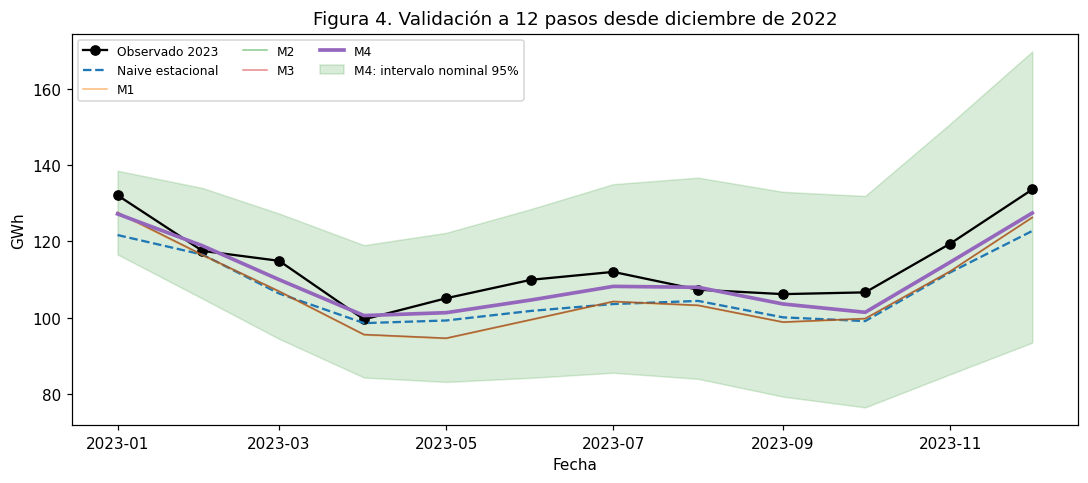

Origen 2020-12: 72 meses → validación 2021


  M1: convergió en 0.1 s


  M2: convergió en 0.2 s


  M3: convergió en 0.5 s


  M4: convergió en 0.0 s


...

  M2: convergió en 0.3 s


  M3: convergió en 0.4 s


  M4: convergió en 0.1 s


Tabla 3. Comparación oficial y origen móvil; errores en GWh.
¹ AIC/BIC solo del ajuste 2015–2022. No se comparan entre orígenes ni se promedian.
RMSE agregado = raíz de la media de los 36 errores cuadrados; no media de RMSE anuales.


Avisos capturados: 1
Aviso de ajuste: (2022, 'M4', 'Maximum Likelihood optimization failed to converge. Check mle_retvals')
RMSE 2021–2022 (24 meses): {'M1': 5.535, 'M2': 5.818, 'M3': 5.594, 'M4': 9.421, 'Naive estacional': 8.226}


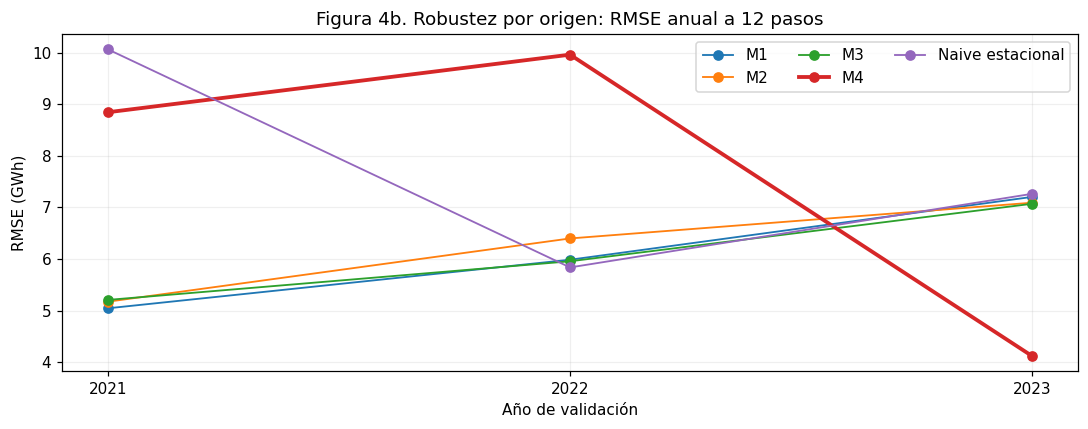

In [4]:
# definir las métricas en la escala original
def rmse(error): return float(np.sqrt(np.mean(np.square(error))))
def mae(error): return float(np.mean(np.abs(error)))
# usar el último año de entrenamiento como referencia estacional
naive_val = pd.Series(y_train.iloc[-12:].to_numpy(), index=y_val.index)
predicciones, intervalos, filas = {}, {}, []
# pronosticar doce meses sin actualizar con la validación
for nombre, ajuste in ajustes.items():
    futuro = ajuste.get_forecast(steps=12)
    # corregir el sesgo al volver desde la escala logarítmica
    media = np.exp(futuro.predicted_mean + .5*futuro.var_pred_mean)
    limites = np.exp(futuro.conf_int(alpha=ALFA))
    assert media.index.equals(y_val.index)
    assert np.isfinite(media).all() and np.isfinite(limites).all().all()
    predicciones[nombre], intervalos[nombre] = media, limites
    error = y_val - media
    filas.append([nombre, ajuste.aic, ajuste.bic, rmse(error), mae(error)])
filas.append(['Naive estacional', np.nan, np.nan,
              rmse(y_val-naive_val),mae(y_val-naive_val)])
# comparar el ajuste y los errores fuera de muestra
tabla3 = pd.DataFrame(filas,columns=['Modelo','AIC','BIC','RMSE GWh','MAE GWh']).set_index('Modelo')
print('Tabla 3. Comparación homogénea: entrenamiento 2015–2022, validación 2023.')
# La tabla se muestra ampliada al final, para mantener una tabla en esta sección.
# elegir el menor RMSE entre los modelos ajustados
seleccionado = tabla3.loc[list(ajustes),'RMSE GWh'].idxmin()
modelo_final = ajustes[seleccionado]
mejora_rmse = 100*(1-tabla3.loc[seleccionado,'RMSE GWh']/tabla3.loc['Naive estacional','RMSE GWh'])
mejora_mae = 100*(1-tabla3.loc[seleccionado,'MAE GWh']/tabla3.loc['Naive estacional','MAE GWh'])
# medir la cobertura observada de los intervalos
limites = intervalos[seleccionado]
cobertura = ((y_val>=limites.iloc[:,0])&(y_val<=limites.iloc[:,1])).mean()
print(f'Seleccionado: {seleccionado}; mejora RMSE {mejora_rmse:.2f}%; mejora MAE {mejora_mae:.2f}%.')
print(f'Cobertura descriptiva de intervalos nominales 95%: {cobertura:.1%} ({len(y_val)} meses).')
print('No se reajusta con 2023 ni se pronostica/evalúa 2024 en esta semana.')
# comparar los pronósticos con el consumo de 2023
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(y_val, 'o-', color='black',label='Observado 2023')
ax.plot(naive_val, '--',label='Naive estacional')
for nombre, pred in predicciones.items():
    ax.plot(pred, lw=2.4 if nombre==seleccionado else 1,
            alpha=1 if nombre==seleccionado else .55,label=nombre)
ax.fill_between(y_val.index,limites.iloc[:,0],limites.iloc[:,1],alpha=.15,color='green',
                label=f'{seleccionado}: intervalo nominal 95%')
ax.set(title='Figura 4. Validación a 12 pasos desde diciembre de 2022',ylabel='GWh',xlabel='Fecha')
ax.legend(ncol=3,fontsize=8)
mostrar_figura(fig,'s2_04_validacion.png')


# Comprobación retrospectiva solicitada por el docente: origen móvil anual.
# Se mantienen los órdenes ya identificados; cada modelo se REESTIMA con su pasado.
# No se cambian ajustes, modelo_final ni seleccionado del experimento oficial 2023.
from time import perf_counter
origenes = [pd.Timestamp(f'{anio}-12-01') for anio in (2020, 2021, 2022)]
errores_om, filas_om, avisos_om = {}, [], []
for origen in origenes:
    entrenamiento_om = y.loc[:origen]
    fechas_om = pd.date_range(origen + pd.offsets.MonthBegin(1), periods=12, freq='MS')
    real_om = y.reindex(fechas_om)
    assert entrenamiento_om.index.max() < real_om.index.min()
    assert real_om.notna().all() and real_om.index.max().year <= 2023
    anio = int(real_om.index[0].year)
    print(f'Origen {origen:%Y-%m}: {len(entrenamiento_om)} meses → validación {anio}', flush=True)
    for nombre, (orden, estacional, _) in candidatos.items():
        inicio_om = perf_counter()
        modelo_om = SARIMAX(np.log(entrenamiento_om), order=orden,
            seasonal_order=estacional, trend='n', enforce_stationarity=True,
            enforce_invertibility=True, simple_differencing=False)
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter('always')
            ajuste_om = modelo_om.fit(method='lbfgs', maxiter=500, disp=False)
            # Si L-BFGS no converge, repito el ajuste con Powell y verifico el resultado final.
            if not ajuste_om.mle_retvals.get('converged', False):
                ajuste_om = modelo_om.fit(method='powell', maxiter=1000, disp=False)
        for aviso in avisos:
            avisos_om.append((anio, nombre, str(aviso.message)))
        assert ajuste_om.mle_retvals.get('converged', False), f'{anio}/{nombre}: no convergió'
        futuro_om = ajuste_om.get_forecast(12)
        media_om = np.exp(futuro_om.predicted_mean + .5*futuro_om.var_pred_mean)
        assert media_om.index.equals(real_om.index) and np.isfinite(media_om).all()
        error_om = (real_om - media_om).to_numpy()
        errores_om[(anio,nombre)] = error_om
        filas_om.append([anio,nombre,rmse(error_om),mae(error_om)])
        # El origen 2022 reproduce el experimento oficial, no añade otro test independiente.
        if anio == 2023:
            np.testing.assert_allclose(media_om.to_numpy(),predicciones[nombre].to_numpy(),rtol=1e-5,atol=1e-5)
        print(f'  {nombre}: convergió en {perf_counter()-inicio_om:.1f} s', flush=True)
    naive_om = entrenamiento_om.iloc[-12:].to_numpy()
    error_naive_om = real_om.to_numpy() - naive_om
    errores_om[(anio,'Naive estacional')] = error_naive_om
    filas_om.append([anio,'Naive estacional',rmse(error_naive_om),mae(error_naive_om)])

metricas_om = pd.DataFrame(filas_om,columns=['Año','Modelo','RMSE GWh','MAE GWh'])
modelos_om = list(candidatos)+['Naive estacional']
filas_integradas = []
for anio in (2021,2022,2023):
    for nombre in modelos_om:
        error_om = errores_om[(anio,nombre)]
        filas_integradas.append([str(anio),nombre,
            tabla3.loc[nombre,'AIC'] if anio==2023 else np.nan,
            tabla3.loc[nombre,'BIC'] if anio==2023 else np.nan,
            rmse(error_om),mae(error_om)])
for nombre in modelos_om:
    error_total = np.concatenate([errores_om[(a,nombre)] for a in (2021,2022,2023)])
    filas_integradas.append(['2021–2023 (36 meses)',nombre,np.nan,np.nan,rmse(error_total),mae(error_total)])
tabla3_ampliada = pd.DataFrame(filas_integradas,columns=[
    'Validación','Modelo','AIC¹','BIC¹','RMSE GWh','MAE GWh']).set_index(['Validación','Modelo'])
print('Tabla 3. Comparación oficial y origen móvil; errores en GWh.')
print('¹ AIC/BIC solo del ajuste 2015–2022. No se comparan entre orígenes ni se promedian.')
print('RMSE agregado = raíz de la media de los 36 errores cuadrados; no media de RMSE anuales.')
display(tabla3_ampliada.style.format('{:.3f}',na_rep='—'))
print('Avisos capturados:',len(avisos_om))
for aviso in avisos_om: print('Aviso de ajuste:',aviso)
# Los dos años nuevos respecto del análisis inicial se resumen también por separado.
resumen_pre2023 = {nombre: {
    'RMSE': rmse(np.concatenate([errores_om[(a,nombre)] for a in (2021,2022)])),
    'MAE': mae(np.concatenate([errores_om[(a,nombre)] for a in (2021,2022)]))}
    for nombre in modelos_om}
print('RMSE 2021–2022 (24 meses):', {k:round(v['RMSE'],3) for k,v in resumen_pre2023.items()})
fig, ax = plt.subplots(figsize=(10,4))
for nombre in modelos_om:
    tramo = metricas_om[metricas_om.Modelo==nombre]
    ax.plot(tramo['Año'],tramo['RMSE GWh'],'o-',label=nombre,
            linewidth=2.5 if nombre=='M4' else 1.2)
ax.set(title='Figura 4b. Robustez por origen: RMSE anual a 12 pasos',
       xlabel='Año de validación',ylabel='RMSE (GWh)',xticks=[2021,2022,2023])
ax.legend(ncol=3);ax.grid(alpha=.2)
mostrar_figura(fig,'s2_04b_origen_movil.png')


### Interpretación

En la validación oficial 2023, M4 obtiene RMSE = 4,123 y MAE = 3,710 GWh, frente a 7,263 y 6,528 del naive: mejoras de 43,24 % y 43,18 %. M1 gana AIC/BIC (−300,040/−295,203), pero tiene RMSE = 7,202. Se mantiene M4 como selección específica de esa partición, no como ganador universal.

La comprobación solicitada no respalda una ventaja persistente del AR estacional. En 2021, M4 registra RMSE = 8,839 frente a 5,041 de M1; en 2022, 9,965 frente a 5,909. El naive gana en 2022 (5,837). En los 24 meses adicionales, M1 obtiene RMSE = 5,492 y M4 = 9,419 GWh.

En los 36 errores de 2021–2023, M1 alcanza RMSE/MAE = 6,115/5,497; M4, 8,050/6,624; y naive, 7,918/6,655 GWh. M1 presenta mejor desempeño agregado, aunque queda muy próximo a M2 y M3. No se demuestra una diferencia estadísticamente significativa.

Todos los ajustes finales convergen; M4 para 2021 y M3 para 2022 necesitaron Powell tras el intento L-BFGS. Los avisos se conservan. AIC/BIC se comparan solo en el entrenamiento común 2015–2022; la media retransformada usa varianza predictiva por horizonte.

Los candidatos se definieron con información posterior a los primeros cortes: esta evaluación retrospectiva, sobre el CSV ya depurado, no es un test independiente. No se usa 2024. M1 merece diagnóstico adicional antes de adoptarlo para uso general; M4 conserva el diagnóstico del experimento oficial.


## 4. Diagnóstico de residuos y validación de supuestos

**ID 2.2.** Se analizan errores de predicción a un paso del ajuste de entrenamiento, en escala logarítmica, excluyendo el máximo entre `loglikelihood_burn` y d + 12D. Ljung–Box usa `model_df = p + q + P + Q`; ARCH-LM usa 12 rezagos y la misma corrección de grados de libertad. Se añaden media cero y Levene por tercios cronológicos como controles complementarios (Rosas, 2026; statsmodels, s. f.).

Tabla 4. Diagnóstico M4; excluidos 13, n=83, model_df=1.

,H₀,Estadístico,p,"Decisión α=0,05"
Prueba,,,,
Ljung–Box 12,Sin autocorrelación hasta 12,8.3829,0.6786,No rechazar H₀
Ljung–Box 24,Sin autocorrelación hasta 24,34.4070,0.0595,No rechazar H₀
Shapiro–Wilk,Normalidad,0.9840,0.3926,No rechazar H₀
ARCH-LM 12,Sin efecto ARCH hasta 12,7.8726,0.7950,No rechazar H₀
t de media cero,Media igual a cero,-0.0170,0.9864,No rechazar H₀
Levene por tercios,Igual varianza entre tres períodos,2.1652,0.1214,No rechazar H₀


Media residual: -0.000083; desviación: 0.044449.
Varianzas por tercio: [np.float64(0.001114), np.float64(0.002737), np.float64(0.002158)]
Tres mayores residuos absolutos (fecha: magnitud): {'2020-04-01': 0.1468, '2021-03-01': 0.0954, '2016-02-01': 0.0912}
Mínimo módulo raíz AR: 1.1022484868345641


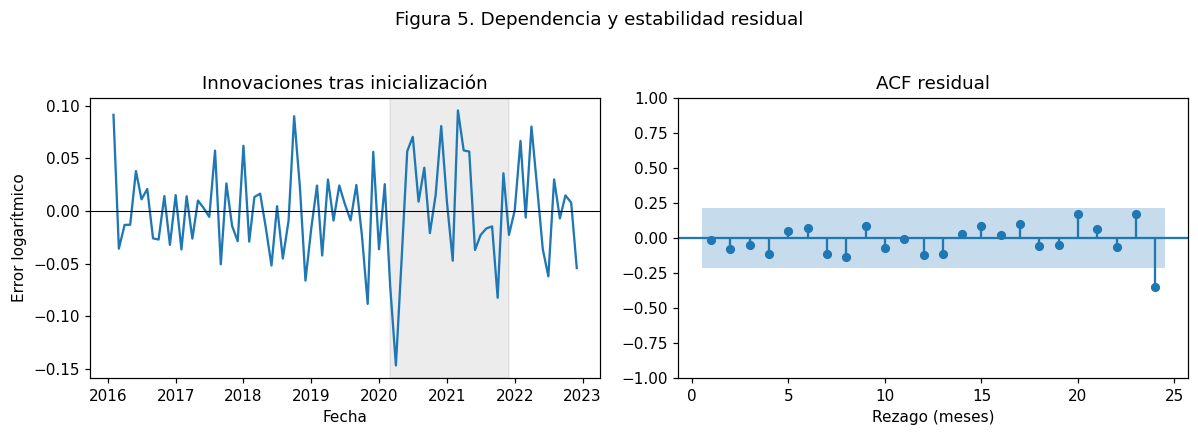

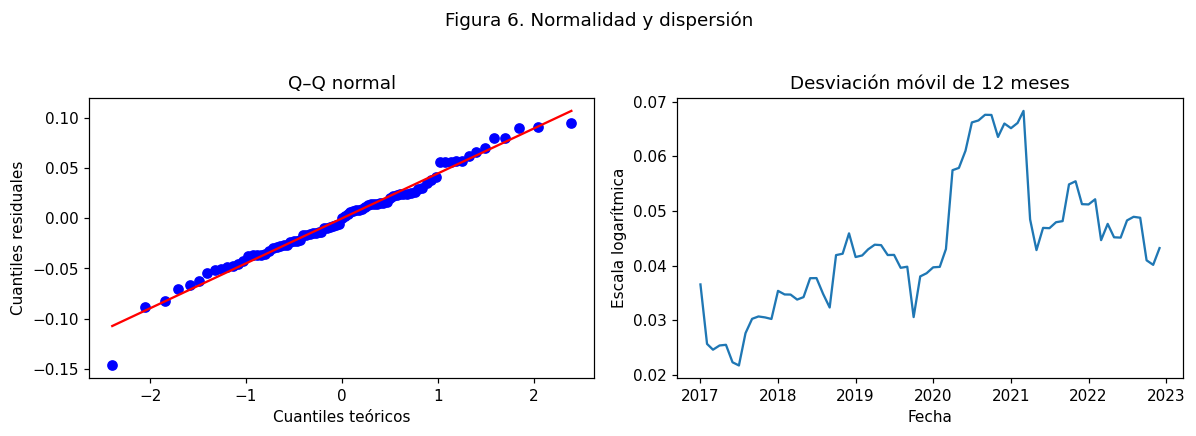

In [5]:
# calcular los grados de libertad y retirar la inicialización
orden, estacional, _ = candidatos[seleccionado]
model_df = orden[0]+orden[2]+estacional[0]+estacional[2]
burn = max(int(modelo_final.loglikelihood_burn), orden[1]+estacional[1]*estacional[3])
residuos = modelo_final.resid.iloc[burn:].dropna()
assert len(residuos)>24 and 12>model_df
# evaluar la autocorrelación y la normalidad residual
lb = acorr_ljungbox(residuos,lags=[12,24],model_df=model_df,return_df=True)
sh = stats.shapiro(residuos)
# comprobar efectos de varianza condicional
with warnings.catch_warnings():
    warnings.simplefilter('ignore', FutureWarning)
    arch = het_arch(residuos,nlags=12,ddof=model_df)
# revisar la media y la dispersión por períodos
tmedia = stats.ttest_1samp(residuos, popmean=0)
tercios = np.array_split(residuos.to_numpy(),3)
lev = stats.levene(*tercios,center='median')
# reunir los diagnósticos y sus hipótesis nulas
filas = [
 ['Ljung–Box 12','Sin autocorrelación hasta 12',lb.loc[12,'lb_stat'],lb.loc[12,'lb_pvalue']],
 ['Ljung–Box 24','Sin autocorrelación hasta 24',lb.loc[24,'lb_stat'],lb.loc[24,'lb_pvalue']],
 ['Shapiro–Wilk','Normalidad',sh.statistic,sh.pvalue],
 ['ARCH-LM 12','Sin efecto ARCH hasta 12',arch[0],arch[1]],
 ['t de media cero','Media igual a cero',tmedia.statistic,tmedia.pvalue],
 ['Levene por tercios','Igual varianza entre tres períodos',lev.statistic,lev.pvalue]
]
# evaluar cada prueba al nivel de significancia elegido
tabla4 = pd.DataFrame(filas,columns=['Prueba','H₀','Estadístico','p']).set_index('Prueba')
tabla4['Decisión α=0,05'] = np.where(tabla4['p']<ALFA,'Rechazar H₀','No rechazar H₀')
print(f'Tabla 4. Diagnóstico {seleccionado}; excluidos {burn}, n={len(residuos)}, model_df={model_df}.')
display(tabla4.style.format({'Estadístico':'{:.4f}','p':'{:.4f}'}))
print(f'Media residual: {residuos.mean():.6f}; desviación: {residuos.std():.6f}.')
print('Varianzas por tercio:',[round(np.var(t,ddof=1),6) for t in tercios])
print('Tres mayores residuos absolutos (fecha: magnitud):',
      {str(k.date()):round(v,4) for k,v in residuos.abs().nlargest(3).items()})
print('Mínimo módulo raíz AR:', float(np.min(np.abs(modelo_final.arroots))))
# visualizar los residuos y sus supuestos
fig, ax = plt.subplots(1,2,figsize=(11,3.8))
ax[0].plot(residuos); ax[0].axhline(0,color='black',lw=.7)
ax[0].set(title='Innovaciones tras inicialización',ylabel='Error logarítmico',xlabel='Fecha')
ax[0].axvspan(pd.Timestamp('2020-03-01'),pd.Timestamp('2021-12-01'),color='gray',alpha=.15)
plot_acf(residuos,lags=24,zero=False,ax=ax[1],bartlett_confint=False)
ax[1].set(xlabel='Rezago (meses)',title='ACF residual')
fig.suptitle('Figura 5. Dependencia y estabilidad residual',y=1.03)
mostrar_figura(fig,'s2_05_residuos.png')
# comparar la distribución residual observada con la normal
fig, ax = plt.subplots(1,2,figsize=(11,3.8))
stats.probplot(residuos,dist='norm',plot=ax[0]); ax[0].set(title='Q–Q normal',xlabel='Cuantiles teóricos',ylabel='Cuantiles residuales')
ax[1].plot(residuos.rolling(12).std()); ax[1].set(title='Desviación móvil de 12 meses',ylabel='Escala logarítmica',xlabel='Fecha')
fig.suptitle('Figura 6. Normalidad y dispersión',y=1.03)
mostrar_figura(fig,'s2_06_supuestos.png')


### Interpretación

Tras retirar 13 innovaciones iniciales quedan 83 residuos. Ljung–Box no rechaza ausencia de autocorrelación al 5 %: p = 0,6789 en 12 y p = 0,0594 en 24, descontando un parámetro AR estacional. El segundo resultado es fronterizo: al 10 % cambiaría la decisión. No constituye evidencia contundente de ruido blanco ni descarta dependencia en otros rezagos.

Shapiro–Wilk no rechaza normalidad (p = 0,3924). La prueba de media cero tampoco rechaza (p = 0,9864); su interpretación supone dependencia residual suficientemente débil. ARCH-LM no detecta heterocedasticidad condicional hasta 12 rezagos (p = 0,7952), pero no prueba homocedasticidad general. Levene por tercios no rechaza igualdad de varianzas (p = 0,1214); la dispersión móvil complementa esa evaluación.

El mayor error absoluto corresponde a abril de 2020 (0,1468 en escala logarítmica), dentro de la ventana COVID. La coincidencia no demuestra causalidad. No se elimina ese mes ni se modifican los datos para conseguir p-valores favorables.

M4 resulta utilizable con reservas para la partición oficial 2023: los controles exigidos no rechazan al 5 %, pero la muestra es corta, existe sensibilidad en el rezago 24 y el origen móvil no confirma su ventaja. Los intervalos gaussianos siguen sujetos a estabilidad y especificación. Si la dependencia persiste en una evaluación posterior, corresponde revisar la estructura estacional; GARCH solo sería pertinente ante evidencia de varianza condicional, no como solución automática a cualquier fallo.

## Conclusiones

1. La evidencia conjunta de pruebas, gráficos y varianza sustenta trabajar con logaritmo, una diferencia regular y una estacional anual. La discordancia inicial ADF/KPSS se reconoce; no se oculta ni se decide solo por un p-valor.
2. Se estiman cuatro candidatos acotados. La lectura del correlograma no reproduce automáticamente el modelo de pasajeros y la selección distingue ajuste penalizado de desempeño predictivo.
3. M4 reduce RMSE y MAE aproximadamente un 43 % frente al naive en 2023 y conserva la selección en la partición oficial. Sin embargo, su ventaja no se sostiene en 2021 ni 2022. El RMSE agregado 2021–2023 favorece a M1 (6,115 GWh) frente a M4 (8,050 GWh); el naive obtiene 7,918 GWh. La retroalimentación permite acotar la conclusión original: el ganador depende del período. Para una elección basada en varios orígenes, M1 es el candidato preferente por errores, sujeto a diagnóstico antes de su adopción.
4. Los diagnósticos exigidos no rechazan al 5 %, con advertencia específica por Ljung–Box en 24. La perturbación de 2020 y la incertidumbre de selección justifican mantener una conclusión condicional.

**Trazabilidad con la rúbrica:** estacionariedad → Tabla 1/Figuras 1–2; identificación y estimación → Tabla 2/Figura 3; comparación y origen móvil → Tabla 3/Figuras 4 y 4b; diagnóstico → Tabla 4/Figuras 5–6. Las cuatro interpretaciones respetan el máximo de 250 palabras. Se conserva una tabla por sección técnica y la hoja de decisiones antes del desarrollo.



## 10. Referencias y declaración de apoyo

### 10.1 Referencias bibliográficas

Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3rd ed.). OTexts. https://otexts.com/fpp3/  
Secciones consultadas: capítulos 5 (retransformación y evaluación) y 9 (identificación y estimación ARIMA).

Rosas, H. (2026, 12 de octubre). *MCDI505: Guía de compañía. Semana 2* [Guía docente]. Universidad Andrés Bello. Archivo proporcionado: `MCDI505_S2_guia_de_compania.pdf`.

Universidad Andrés Bello. (s. f.-a). *Análisis de series de tiempo (MCDI505): Sumativa 2 — Informe técnico de modelos clásicos (ARIMA/SARIMA)* [Instrucciones y rúbrica, versión 2]. Archivo proporcionado: `MCDI505_Sumativa2_instrucciones_v2.pdf`.

Universidad Andrés Bello. (s. f.-b). *MCDI505: Semana 2 — Modelos clásicos (ARIMA/SARIMA)* [Plantilla de notebook]. Archivo proporcionado: `mcdi505_s2_plantilla.ipynb`.

statsmodels. (s. f.). *statsmodels.stats.diagnostic.acorr_ljungbox* [Documentación de software]. Recuperado el 14 de octubre de 2026, de https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html

**Procedencia de los datos:** archivo `consumo_electrico_litoral_depurado.csv` adjunto a la actividad, tratado como versión del caso indicada por las instrucciones; no se atribuye una fuente externa no verificada. La huella SHA-256 de la celda de configuración identifica exactamente los bytes utilizados. El notebook de Sumativa 1 aportó nombres, convenciones y contexto; sus decisiones de limpieza no reemplazan el CSV de esta semana.

### 10.2 Declaración de uso de IA

Se utilizó inteligencia artificial como apoyo en la organización del notebook, la revisión del código y la mejora de la redacción y la ortografía.


En la revisión posterior al feedback se utilizó además asistencia para implementar y ejecutar la validación con origen móvil, comparar sus resultados y actualizar las interpretaciones. La ejecución del asistente no sustituye la revisión independiente del estudiante.